In [1]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from prophet import Prophet

O Prophet é uma ferramenta de previsão de séries temporais, que são dados coletados ao longo do tempo, como os preços das ações. Ele foi desenvolvido pelo Facebook (atual Meta). É prático para testar tendências e sazonalidades, mas a qualidade das previsões depende dos dados e dos padrões presentes 


Vamos usar dados das ações da Johnson & Johnson como exemplo. Aqui baixamos preços históricos de 2020 até o final de 2023 (a data final do download é exclusiva).

In [2]:
# Baixar dados dos últimos quatro anos para uma ação específica
dados = yf.download("JNJ", start="2020-01-01", end="2023-12-31", progress=False, auto_adjust=False)
dados = dados.reset_index()
dados
# Compatibilidade com versões do yfinance que retornam colunas MultiIndex
if isinstance(dados.columns, pd.MultiIndex):
    dados.columns = dados.columns.get_level_values(0)


Agora dividimos os dados em duas partes: uma para treinar nosso 'adivinho' digital, com datas anteriores a 31/07/2023, e outra para testar as previsões, a partir de 31/07/2023.

In [3]:
# Vamos dividir em treino (antes de 31/07/2023) e teste (a partir de 31/07/2023)
dados_treino = dados[dados['Date'] < '2023-07-31']
dados_teste = dados[dados['Date'] >= '2023-07-31']

In [4]:
# Preparando os dados para o Prophet
dados_prophet_treino = dados_treino[['Date', 'Close']].rename(columns={'Date': 'ds', 'Close': 'y'})

O próximo passo é preparar os dados para o nosso adivinho, o Prophet. É como se estivéssemos arrumando os dados para que ele entenda o que estamos perguntando.

Depois, criamos o modelo do Prophet. Aqui, estamos dizendo ao Prophet para considerar padrões semanais e anuais nos dados, mas não diários. E também adicionamos feriados dos EUA, já que eles podem influenciar o preço das ações.

In [5]:
# Criar e treinar o modelo
modelo = Prophet(weekly_seasonality=True,
        yearly_seasonality=True,
        daily_seasonality=False)

modelo.add_country_holidays(country_name='US')

modelo.fit(dados_prophet_treino)

c:\Users\bruco\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
20:35:07 - cmdstanpy - INFO - Chain [1] start processing
20:35:08 - cmdstanpy - INFO - Chain [1] done processing


Pedimos ao Prophet para gerar previsões para 150 dias depois da última data de treino (além das datas históricas). Isso alcança aproximadamente o fim de 2023, mas não define exatamente 31 de dezembro. Depois plotamos o gráfico para comparar a previsão com os dados reais.

In [6]:
# Criar 150 dias futuros a partir da última data do treino
futuro = modelo.make_future_dataframe(periods=150)
previsao = modelo.predict(futuro)

Vamos criar agora um gráfico com três linhas. A azul mostra os preços reais usados no treino, a verde mostra os preços reais reservados para teste e a laranja mostra o que o Prophet previu. A linha vermelha pontilhada marca a última data do treino, ou seja, a divisão entre treino e teste.

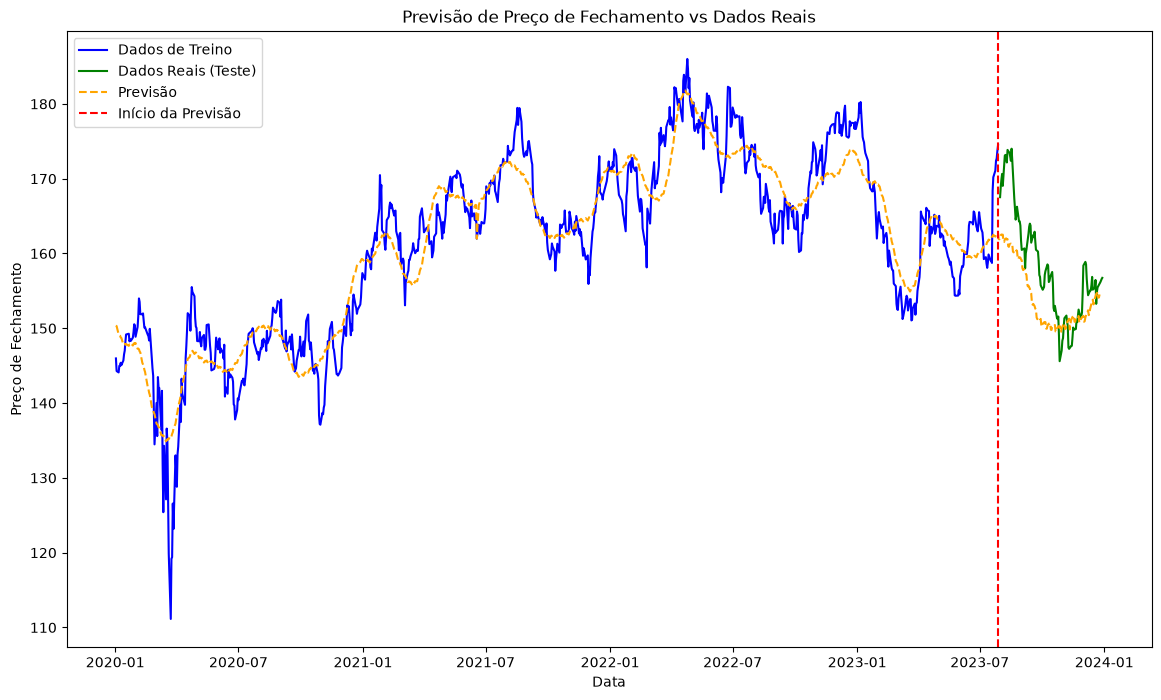

In [7]:
# Plotar os dados de treino, teste e previsões
plt.figure(figsize=(14, 8))
plt.plot(dados_treino['Date'], dados_treino['Close'], label='Dados de Treino', color='blue')
plt.plot(dados_teste['Date'], dados_teste['Close'], label='Dados Reais (Teste)', color='green')
plt.plot(previsao['ds'], previsao['yhat'], label='Previsão', color='orange', linestyle='--')

plt.axvline(dados_treino['Date'].max(), color='red', linestyle='--', label='Início da Previsão')
plt.xlabel('Data')
plt.ylabel('Preço de Fechamento')
plt.title('Previsão de Preço de Fechamento vs Dados Reais')
plt.legend()
plt.show()